# Ejemplo Python - California Housing
---

Descripción del dataset California Housing

Origen: Datos del censo de California de 1990.
Objetivo: Predecir el valor medio de las casas en diferentes distritos de California.
Número de muestras: 20,640 registros.
Número de características: 8 variables predictoras + 1 variable objetivo.


Variables

MedInc: Ingreso medio de los hogares en el distrito (en decenas de miles de dólares).
HouseAge: Edad media de las casas en el distrito.
AveRooms: Promedio de habitaciones por hogar.
AveBedrms: Promedio de dormitorios por hogar.
Population: Población total del distrito.
AveOccup: Promedio de ocupantes por hogar.
Latitude: Latitud del distrito.
Longitude: Longitud del distrito.

Variable objetivo:

Price (target): Valor medio de las casas (en cientos de miles de dólares).

In [1]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Cargar el dataset
california = fetch_california_housing()
X = pd.DataFrame(california.data, columns=california.feature_names)
y = pd.Series(california.target, name="Price")

# Ver tipos de datos
print("Tipos de datos de las variables predictoras:")
print(X.dtypes)

print("\nTipo de dato de la variable objetivo:")
print(y.dtype)

Tipos de datos de las variables predictoras:
MedInc        float64
HouseAge      float64
AveRooms      float64
AveBedrms     float64
Population    float64
AveOccup      float64
Latitude      float64
Longitude     float64
dtype: object

Tipo de dato de la variable objetivo:
float64


Resumen del Dataset California Housing

Observaciones: 20,640.
Variables predictoras (todas numéricas continuas):

MedInc: Ingreso medio (decenas de miles de dólares).
HouseAge: Edad promedio de las casas.
AveRooms: Promedio de habitaciones por hogar.
AveBedrms: Promedio de dormitorios por hogar.
Population: Población total del distrito.
AveOccup: Promedio de ocupantes por hogar.
Latitude: Latitud.
Longitude: Longitud.


Variable objetivo: Precio medio de las casas (en cientos de miles de dólares).

## 1. Cargar el dataset

In [6]:
california = fetch_california_housing()
X = california.data
y = california.target

## 2. Dividir datos

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 3. Definir modelo y grilla de parámetros

In [8]:
modelo = DecisionTreeRegressor(random_state=42)
param_grid = {
    'max_depth': [3, 4, 5, 6, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

## 4. Optimización con GridSearchCV

In [9]:
grid_search = GridSearchCV(modelo, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [3, 4, 5, 6, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

## 5. Mejor modelo

In [10]:
mejor_modelo = grid_search.best_estimator_
print("Mejores parámetros:", grid_search.best_params_)

Mejores parámetros: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10}


## 6. Graficar el árbol del mejor modelo

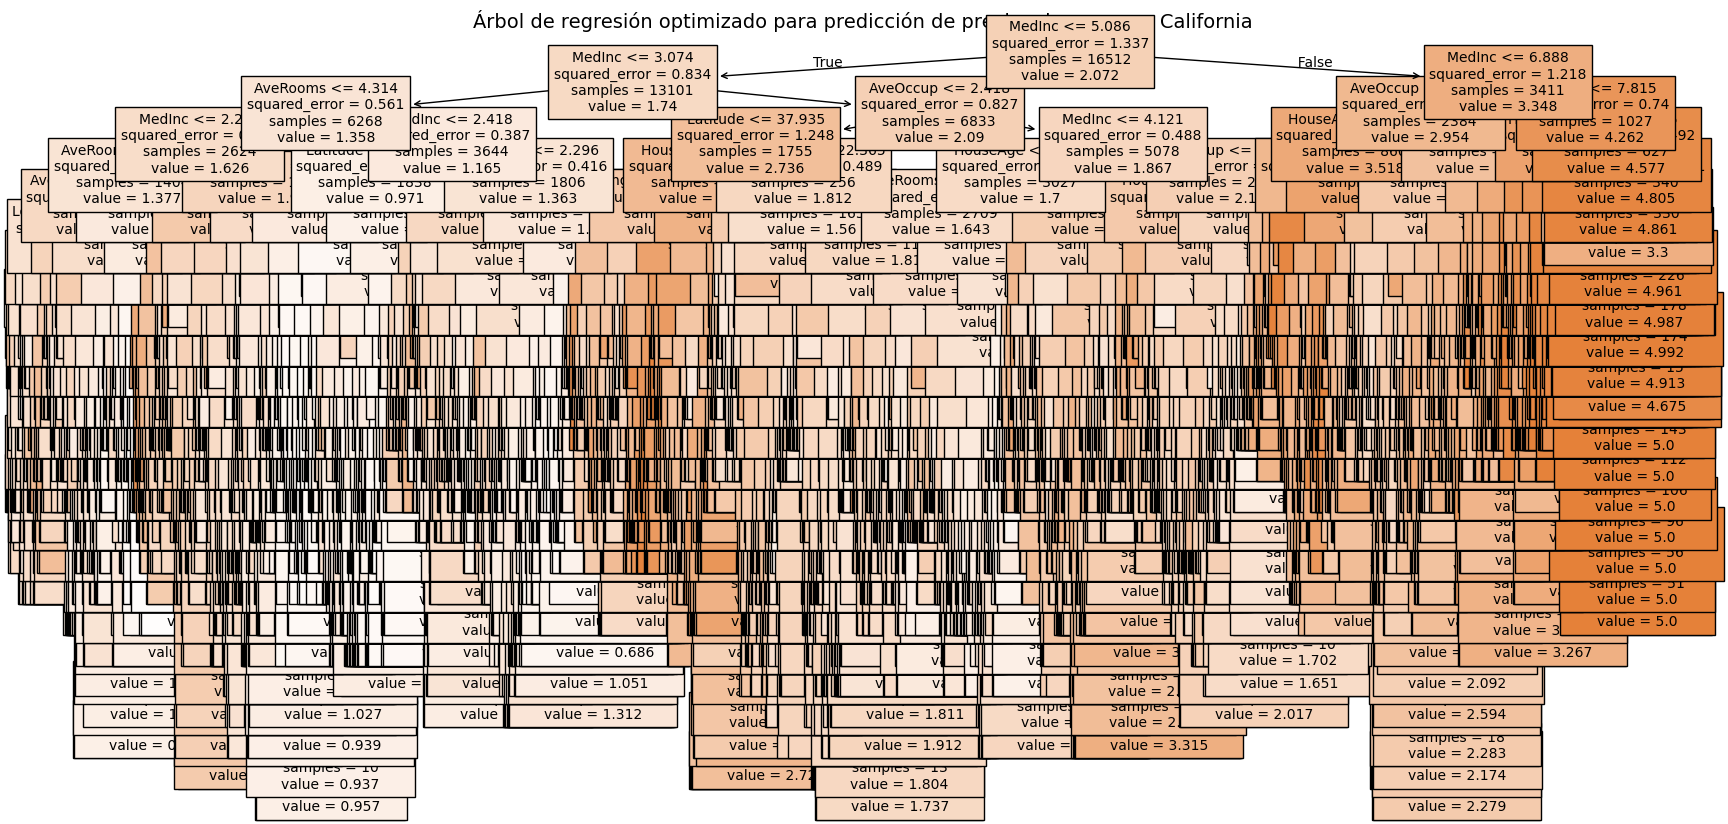

In [11]:
plt.figure(figsize=(20,10))
plot_tree(mejor_modelo, feature_names=california.feature_names, filled=True, fontsize=10)
plt.title("Árbol de regresión optimizado para predicción de precios de casas en California", fontsize=14)
plt.show()

## 1. Cargar el dataset

In [12]:
california = fetch_california_housing()
X = california.data
y = california.target

## 2. Dividir datos

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 3. Entrenar el modelo con max_depth=4

In [14]:
modelo = DecisionTreeRegressor(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=42)

## 4. Graficar el árbol

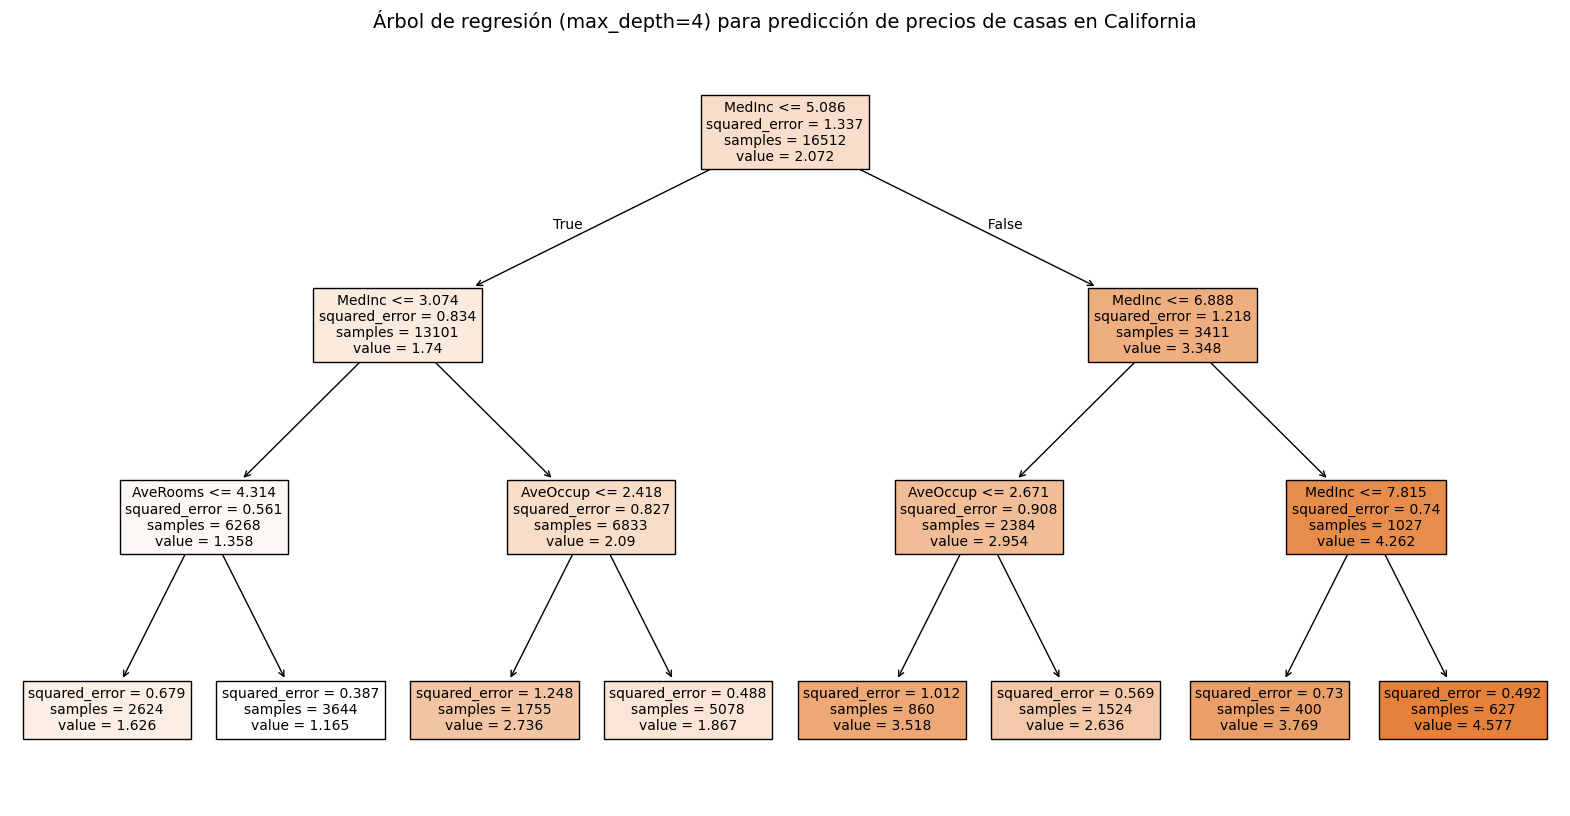

In [15]:
plt.figure(figsize=(20,10))
plot_tree(modelo, feature_names=california.feature_names, filled=True, fontsize=10)
plt.title("Árbol de regresión (max_depth=4) para predicción de precios de casas en California", fontsize=14)
plt.show()